1. Загрузка датасета

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring"
)

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "ml_survival_dataset.parquet"
MODEL_DIR = PROJECT_ROOT / "models" / "survival"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)

print("Размер:", df.shape)
print("Дефолтов:", int(df["event"].sum()))
print("Доля дефолтов:", round(df["event"].mean() * 100, 2), "%")

Размер: (200000, 24)
Дефолтов: 57279
Доля дефолтов: 28.64 %


2. Выбор признаков

In [2]:
FEATURES = [
    "age_months",
    "industry",
    "entity_type",
    "monthly_revenue",
    "revenue_trend_12m",
    "revenue_volatility",
    "operating_margin",
    "cash_buffer_months",
    "dscr",
    "debt_to_revenue",
    "prior_overdue_30d",
    "requested_amount",
    "term_months",
    "annual_rate",
    "macro_stress",
]

CAT_FEATURES = [
    "industry",
    "entity_type",
]

X = df[FEATURES].copy()

for col in CAT_FEATURES:
    X[col] = X[col].fillna("UNKNOWN").astype(str)

print("Признаков:", len(FEATURES))
print("Категориальные:", CAT_FEATURES)

Признаков: 15
Категориальные: ['industry', 'entity_type']


3. Разделение train / validation / test

In [3]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["borrower_id"]

split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42,
)

train_idx, temp_idx = next(
    split_1.split(X, groups=groups)
)

split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42,
)

val_local, test_local = next(
    split_2.split(
        X.iloc[temp_idx],
        groups=groups.iloc[temp_idx],
    )
)

val_idx = temp_idx[val_local]
test_idx = temp_idx[test_local]

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx),
]:
    print(
        name,
        "Доля дефолтов:",
        round(df.iloc[idx]["event"].mean() * 100, 2),
        "%",
    )

Train: 140000
Validation: 30000
Test: 30000
Train Доля дефолтов: 28.65 %
Validation Доля дефолтов: 28.41 %
Test Доля дефолтов: 28.81 %


4. Формирование целевой переменной SurvivalAft

In [4]:
def make_survival_target(data):
    duration = data["duration"].to_numpy(dtype=float)
    event = data["event"].to_numpy(dtype=int)

    lower = duration.copy()

    upper = np.where(
        event == 1,
        duration,
        -1.0,
    )

    return np.column_stack([lower, upper])


y_train = make_survival_target(df.iloc[train_idx])
y_val = make_survival_target(df.iloc[val_idx])
y_test = make_survival_target(df.iloc[test_idx])

print("Пример целевой переменной:")
print(y_train[:10])

Пример целевой переменной:
[[ 8. -1.]
 [ 5.  5.]
 [36. -1.]
 [31. -1.]
 [24. 24.]
 [11. -1.]
 [29. -1.]
 [21. -1.]
 [29. -1.]
 [24. -1.]]


5. Обучение CatBoost SurvivalAft

In [6]:
from catboost import CatBoostRegressor, Pool

train_pool = Pool(
    data=X_train,
    label=y_train,
    cat_features=CAT_FEATURES,
)

val_pool = Pool(
    data=X_val,
    label=y_val,
    cat_features=CAT_FEATURES,
)

model = CatBoostRegressor(
    loss_function="SurvivalAft:dist=Normal;scale=1.0",
    iterations=1000,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=3,
    random_seed=42,
    eval_metric="SurvivalAft:dist=Normal;scale=1.0",
    early_stopping_rounds=100,
    verbose=100,
    thread_count=-1,
)

model.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True,
)

print("Лучшая итерация:", model.best_iteration_)
print("Лучший результат:", model.best_score_)

0:	learn: 19.7151832	test: 19.8395676	best: 19.8395676 (0)	total: 216ms	remaining: 3m 35s
100:	learn: 5.9957796	test: 6.0214724	best: 5.9049252 (89)	total: 6.43s	remaining: 57.2s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 5.904925207
bestIteration = 89

Shrink model to first 90 iterations.
Лучшая итерация: 89
Лучший результат: {'learn': {'SurvivalAft:dist=Normal;scale=1.0': 5.871619525400731}, 'validation': {'SurvivalAft:dist=Normal;scale=1.0': 5.904925206583479}}


6. Настроим папку эксперимента

In [7]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring"
)

EXPERIMENT_NAME = "survival_v3_baseline"

EXPERIMENT_DIR = (
    PROJECT_ROOT
    / "models"
    / "experiments"
    / EXPERIMENT_NAME
)

EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

print("Эксперимент:", EXPERIMENT_DIR)

Эксперимент: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_baseline


7. Сохраним модель и артефакты

In [9]:
import json
import numpy as np
import pandas as pd

# 1. Обученная модель
model.save_model(
    str(EXPERIMENT_DIR / "model.cbm")
)

# 2. Конфигурация обучения
config = {
    "experiment_name": EXPERIMENT_NAME,
    "model_type": "CatBoost SurvivalAft",
    "model_params": model.get_params(),
    "dataset": "ml_survival_dataset.parquet",
    "n_train": len(train_idx),
    "n_val": len(val_idx),
    "n_test": len(test_idx),
    "random_seed": 42,
}

with open(
    EXPERIMENT_DIR / "config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(config, f, ensure_ascii=False, indent=4)

# 3. Признаки
with open(
    EXPERIMENT_DIR / "features.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "features": FEATURES,
            "categorical_features": CAT_FEATURES,
        },
        f,
        ensure_ascii=False,
        indent=4,
    )

# 4. Индексы разбиения
np.savez_compressed(
    EXPERIMENT_DIR / "splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
)

# 5. История обучения
history = model.get_evals_result()

history_rows = {}

for dataset_name, metrics in history.items():
    for metric_name, values in metrics.items():
        history_rows[f"{dataset_name}/{metric_name}"] = values

pd.DataFrame(history_rows).to_csv(
    EXPERIMENT_DIR / "training_history.csv",
    index=False,
)

# 6. Важность признаков
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": model.get_feature_importance(
        data=train_pool,
        type="PredictionValuesChange",
    ),
})

importance = importance.sort_values(
    "importance",
    ascending=False,
)

importance.to_csv(
    EXPERIMENT_DIR / "feature_importance.csv",
    index=False,
)

# 7. Первичные метрики
metrics = {
    "best_iteration": model.best_iteration_,
    "best_score": model.best_score_,
    "train_size": len(train_idx),
    "validation_size": len(val_idx),
    "test_size": len(test_idx),
}

with open(
    EXPERIMENT_DIR / "metrics.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metrics,
        f,
        ensure_ascii=False,
        indent=4,
        default=str,
    )

print("Артефакты сохранены в:", EXPERIMENT_DIR)

for file in sorted(EXPERIMENT_DIR.iterdir()):
    print(" -", file.name)

Артефакты сохранены в: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_baseline
 - config.json
 - feature_importance.csv
 - features.json
 - metrics.json
 - model.cbm
 - splits.npz
 - training_history.csv


Тест

In [10]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor
from scipy.stats import norm

PROJECT_ROOT = Path(
    r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring"
)

EXP_DIR = PROJECT_ROOT / "models" / "experiments" / "survival_v3_baseline"

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" / "ml_survival_dataset.parquet"
)

df = pd.read_parquet(DATA_PATH)

with np.load(EXP_DIR / "splits.npz") as splits:
    test_idx = splits["test_idx"]

with open(EXP_DIR / "features.json", encoding="utf-8") as f:
    feature_config = json.load(f)

FEATURES = feature_config["features"]
CAT_FEATURES = feature_config["categorical_features"]

df_test = df.iloc[test_idx].copy()

X_test = df_test[FEATURES].copy()

for col in CAT_FEATURES:
    X_test[col] = X_test[col].fillna("UNKNOWN").astype(str)

model = CatBoostRegressor()
model.load_model(str(EXP_DIR / "model.cbm"))

print("Тестовых эпизодов:", len(df_test))
print("Дефолтов:", int(df_test["event"].sum()))
print("Признаков:", len(FEATURES))

Тестовых эпизодов: 30000
Дефолтов: 8642
Признаков: 15


Получаем прогнозы SurvivalAft

In [11]:
# Проверяем конфигурацию обученной модели
params = model.get_all_params()

loss_function = params["loss_function"]

print("Loss function:", loss_function)

assert "SurvivalAft" in loss_function
assert "dist=Normal" in loss_function

import re

scale_match = re.search(
    r"scale=([0-9.eE+-]+)",
    loss_function
)

assert scale_match is not None, "Не удалось определить scale"

SCALE = float(scale_match.group(1))

# Прогноз параметра распределения
mu_test = np.asarray(
    model.predict(X_test),
    dtype=float
).reshape(-1)

# Горизонт прогноза — до 60 месяцев
MONTHS = np.arange(1, 61)

# Матрица накопленных вероятностей дефолта
pd_curve = norm.cdf(
    (np.log(MONTHS)[None, :] - mu_test[:, None]) / SCALE
)

# Вероятность дефолта за договорный срок каждого кредита
term = df_test["term_months"].to_numpy(dtype=int)

pd_t = pd_curve[
    np.arange(len(df_test)),
    term - 1
]

print("Форма матрицы PD:", pd_curve.shape)
print("Минимальная PD_T:", pd_t.min())
print("Максимальная PD_T:", pd_t.max())
print("Средняя PD_T:", pd_t.mean())

Loss function: SurvivalAft:dist=Normal;scale=1.0
Форма матрицы PD: (30000, 60)
Минимальная PD_T: 0.1799060528259913
Максимальная PD_T: 0.9788406390641183
Средняя PD_T: 0.491970503382376


In [12]:
assert np.isfinite(pd_curve).all()
assert np.all((pd_curve >= 0) & (pd_curve <= 1))

assert np.all(
    np.diff(pd_curve, axis=1) >= -1e-12
), "Обнаружено уменьшение накопленной PD"

print("Проверка пройдена: кривые PD корректны.")

Проверка пройдена: кривые PD корректны.


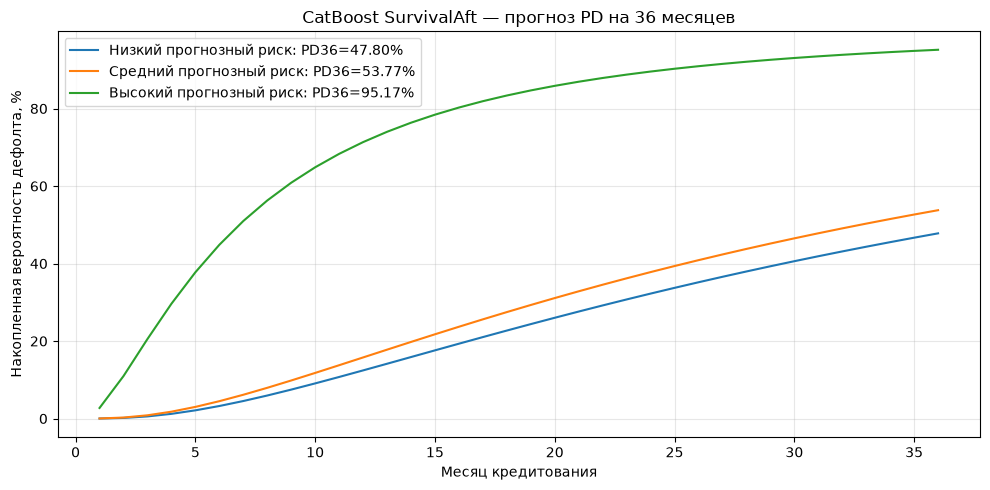

In [13]:
mask_36 = np.where(term == 36)[0]

if len(mask_36) >= 3:
    sorted_idx = mask_36[np.argsort(pd_t[mask_36])]

    selected = [
        sorted_idx[0],
        sorted_idx[len(sorted_idx) // 2],
        sorted_idx[-1],
    ]

    plt.figure(figsize=(10, 5))

    for idx, label in zip(
        selected,
        ["Низкий прогнозный риск", "Средний прогнозный риск", "Высокий прогнозный риск"]
    ):
        plt.plot(
            MONTHS[:36],
            pd_curve[idx, :36] * 100,
            label=f"{label}: PD36={pd_t[idx]:.2%}"
        )

    plt.xlabel("Месяц кредитования")
    plt.ylabel("Накопленная вероятность дефолта, %")
    plt.title("CatBoost SurvivalAft — прогноз PD на 36 месяцев")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        EXP_DIR / "pd_curves_36m.png",
        dpi=160
    )
    plt.show()

In [14]:
from sksurv.metrics import concordance_index_censored, brier_score
from sksurv.util import Surv

# Общий C-index по времени до события
event_test = df_test["event"].to_numpy(dtype=bool)
duration_test = df_test["duration"].to_numpy(dtype=float)

# Чем меньше прогнозируемое время, тем выше риск
risk_score = -mu_test

c_index = concordance_index_censored(
    event_test,
    duration_test,
    risk_score
)[0]

print(f"C-index: {c_index:.4f}")

C-index: 0.6341


In [15]:
with np.load(EXP_DIR / "splits.npz") as splits:
    train_idx = splits["train_idx"]

df_train = df.iloc[train_idx].copy()

train_36 = df_train[df_train["term_months"] == 36]
test_36 = df_test[df_test["term_months"] == 36]

test_positions = np.where(term == 36)[0]

y_train_36 = Surv.from_arrays(
    event=train_36["event"].to_numpy(dtype=bool),
    time=train_36["duration"].to_numpy(dtype=float)
)

y_test_36 = Surv.from_arrays(
    event=test_36["event"].to_numpy(dtype=bool),
    time=test_36["duration"].to_numpy(dtype=float)
)

# Горизонты должны лежать внутри наблюдаемого диапазона.
# Начнём с 6, 12, 18 и 24 месяцев.
times = np.array([6., 12., 18., 24.])

# Вероятность НЕ испытать дефолт к соответствующему месяцу
survival_prob = 1 - pd_curve[
    test_positions[:, None],
    (times.astype(int) - 1)[None, :]
]

valid_times = times[
    (times < train_36["duration"].max()) &
    (times < test_36["duration"].max())
]

survival_prob = survival_prob[:, :len(valid_times)]

brier_times, brier_values = brier_score(
    y_train_36,
    y_test_36,
    survival_prob,
    valid_times
)

brier_df = pd.DataFrame({
    "month": brier_times,
    "brier_score": brier_values,
})

print(brier_df)

brier_df.to_csv(
    EXP_DIR / "brier_score_36m.csv",
    index=False
)

   month  brier_score
0    6.0     0.075168
1   12.0     0.125217
2   18.0     0.167387
3   24.0     0.203540


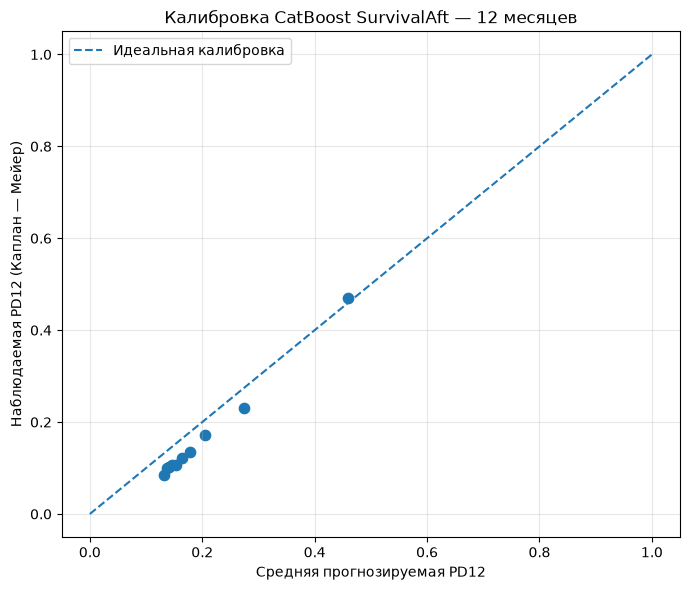

In [16]:
from sksurv.nonparametric import kaplan_meier_estimator

cal = test_36[["duration", "event"]].copy()
cal["predicted_pd12"] = pd_curve[test_positions, 11]

cal["risk_group"] = pd.qcut(
    cal["predicted_pd12"],
    q=10,
    labels=False,
    duplicates="drop"
)

rows = []

for group, part in cal.groupby("risk_group"):
    km_times, km_survival = kaplan_meier_estimator(
        part["event"].astype(bool).to_numpy(),
        part["duration"].astype(float).to_numpy()
    )

    observed_pd = (
        1 - km_survival[km_times <= 12][-1]
        if np.any(km_times <= 12)
        else 0.0
    )

    rows.append({
        "risk_group": int(group),
        "n": len(part),
        "predicted_pd12": part["predicted_pd12"].mean(),
        "observed_pd12": observed_pd,
    })

calibration_df = pd.DataFrame(rows)

calibration_df.to_csv(
    EXP_DIR / "calibration_12m.csv",
    index=False
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Идеальная калибровка"
)

plt.scatter(
    calibration_df["predicted_pd12"],
    calibration_df["observed_pd12"],
    s=55
)

plt.xlabel("Средняя прогнозируемая PD12")
plt.ylabel("Наблюдаемая PD12 (Каплан — Мейер)")
plt.title("Калибровка CatBoost SurvivalAft — 12 месяцев")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    EXP_DIR / "calibration_12m.png",
    dpi=160
)
plt.show()

In [17]:
metrics_path = EXP_DIR / "metrics.json"

with open(metrics_path, encoding="utf-8") as f:
    metrics = json.load(f)

metrics["test_metrics"] = {
    "c_index": float(c_index),
    "mean_pd_t": float(pd_t.mean()),
    "brier_36m": {
        str(int(t)): float(v)
        for t, v in zip(brier_times, brier_values)
    },
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(
        metrics,
        f,
        ensure_ascii=False,
        indent=4
    )

predictions = pd.DataFrame({
    "borrower_id": df_test["borrower_id"].to_numpy(),
    "episode_id": df_test["episode_id"].to_numpy(),
    "term_months": term,
    "duration": duration_test,
    "event": event_test.astype(int),
    "predicted_log_time": mu_test,
    "pd_t": pd_t,
})

for month in MONTHS:
    predictions[f"pd_{month:02d}"] = pd_curve[:, month - 1]

predictions.to_parquet(
    EXP_DIR / "test_predictions.parquet",
    index=False
)

print("Результаты сохранены:", EXP_DIR)
print("C-index:", round(c_index, 4))
print("\nBrier Score:")
print(brier_df)

Результаты сохранены: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_baseline
C-index: 0.6341

Brier Score:
   month  brier_score
0    6.0     0.075168
1   12.0     0.125217
2   18.0     0.167387
3   24.0     0.203540
